# Tarea-Práctica 3: Graficación en Python
**Física Computacional, grupo 8270**

Alexia Dezotti

Fecha: 7 de octubre de 2026

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## 1. Gráfica de datos experimentales

### (a) Leer los datos y graficar todo

In [ ]:
# cargando el archivo
datos = np.loadtxt("manchasolares.txt", float)
mes = datos[:,0]
manchas = datos[:,1]

print(len(mes))  # cuantos datos son

3143


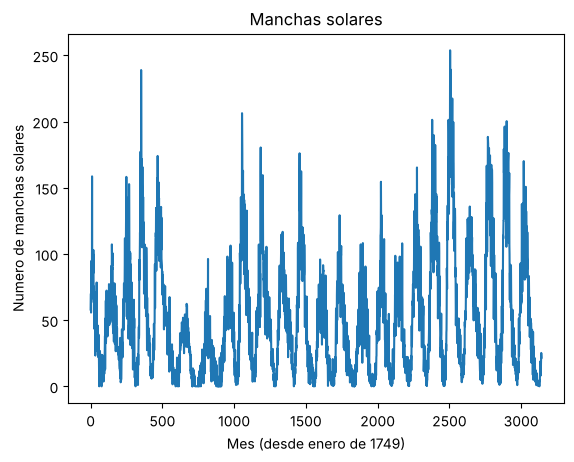

In [3]:
plt.plot(mes, manchas)
plt.xlabel("Mes (desde enero de 1749)")
plt.ylabel("Numero de manchas solares")
plt.title("Manchas solares")
plt.show()

### (b) Solo los primeros 1000 datos

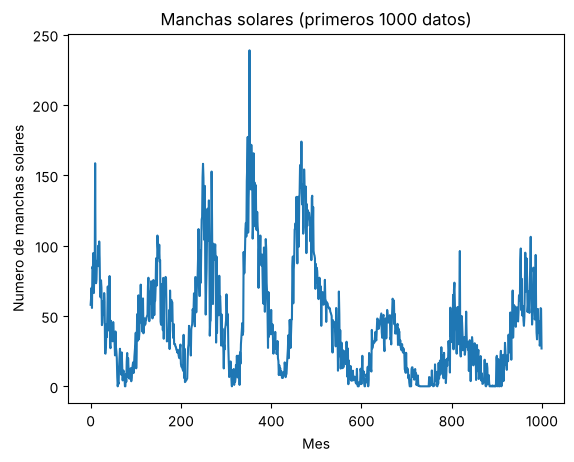

In [4]:
# nada mas corto los arreglos hasta 1000
mes2 = mes[:1000]
manchas2 = manchas[:1000]

plt.plot(mes2, manchas2)
plt.xlabel("Mes")
plt.ylabel("Numero de manchas solares")
plt.title("Manchas solares (primeros 1000 datos)")
plt.show()

### (c) Media móvil

La fórmula es $Y_k = \frac{1}{2r+1}\sum_{m=-r}^{r} y_{k+m}$ con $r=5$.

Para los primeros y ultimos 5 puntos no se puede calcular completa porque se sale del arreglo, entonces empiezo en k=r y termino en N-r.

In [5]:
r = 5
N = len(manchas2)

Y = []
k_lista = []
for k in range(r, N-r):
    suma = 0
    for m in range(-r, r+1):
        suma = suma + manchas2[k+m]
    Y.append(suma/(2*r+1))
    k_lista.append(mes2[k])

print(len(Y))

990


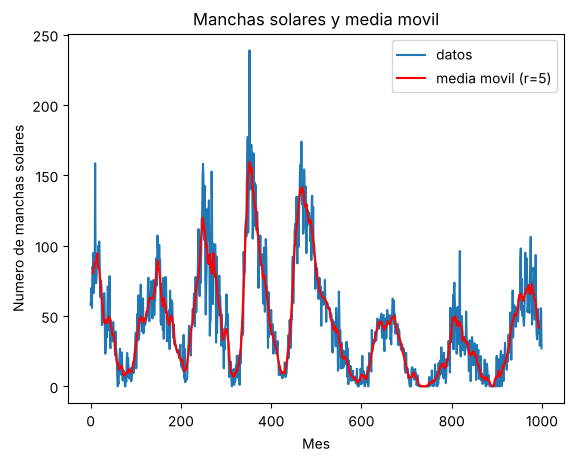

In [6]:
plt.plot(mes2, manchas2, label="datos")
plt.plot(k_lista, Y, "r", label="media movil (r=5)")
plt.xlabel("Mes")
plt.ylabel("Numero de manchas solares")
plt.title("Manchas solares y media movil")
plt.legend()
plt.show()

La media móvil suaviza bastante el ruido y se ve mejor la forma de los ciclos.

## 2. Gráfica de Feigenbaum

### (a) Mapeo logístico $x_{n+1} = r x_n (1-x_n)$

Siguiendo el hint: para cada r empiezo con x = 1/2, itero 1000 veces para que se estabilice y luego otras 1000 veces guardando los puntos.

In [ ]:
r_valores = np.arange(1, 4, 0.01)

r_graf = []
x_graf = []

for r in r_valores:
    x = 0.5
    # primeras 1000 iteraciones (sin graficar)
    for i in range(1000):
        x = r*x*(1-x)
    # otras 1000 y estas si las guardo
    for i in range(1000):
        x = r*x*(1-x)
        r_graf.append(r)
        x_graf.append(x)

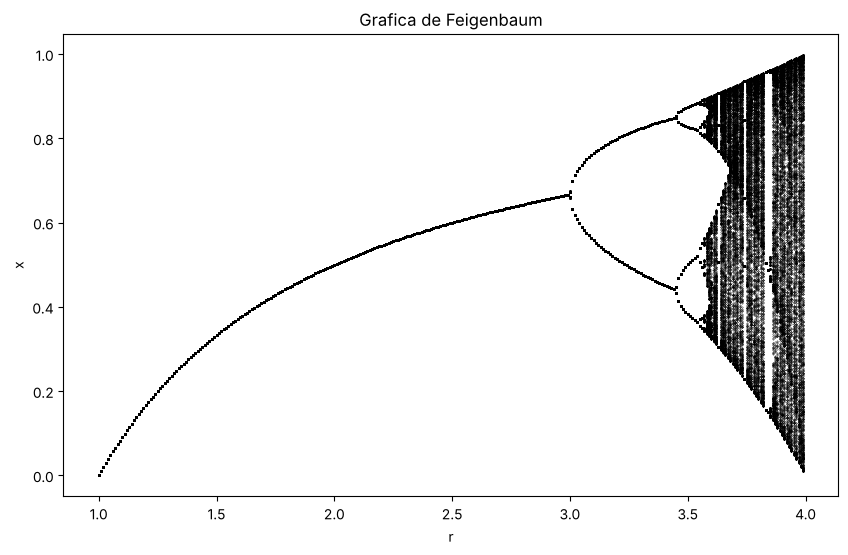

In [8]:
plt.figure(figsize=(10,6))
plt.plot(r_graf, x_graf, "k.", markersize=0.5)
plt.xlabel("r")
plt.ylabel("x")
plt.title("Grafica de Feigenbaum")
plt.show()

### (b) ¿En qué r empieza el caos?

En la gráfica se ve que:
- de r=1 a r=3 hay un solo punto fijo
- en r=3 se divide en 2
- como en r≈3.45 se divide en 4, luego en 8, y cada vez más rápido
- alrededor de **r ≈ 3.5** ya se vuelve caos

Entonces el "borde del caos" está aproximadamente en r ≈ 3.5. (Después todavía hay unas "ventanas" donde vuelve a haber orden, como en r≈3.8).

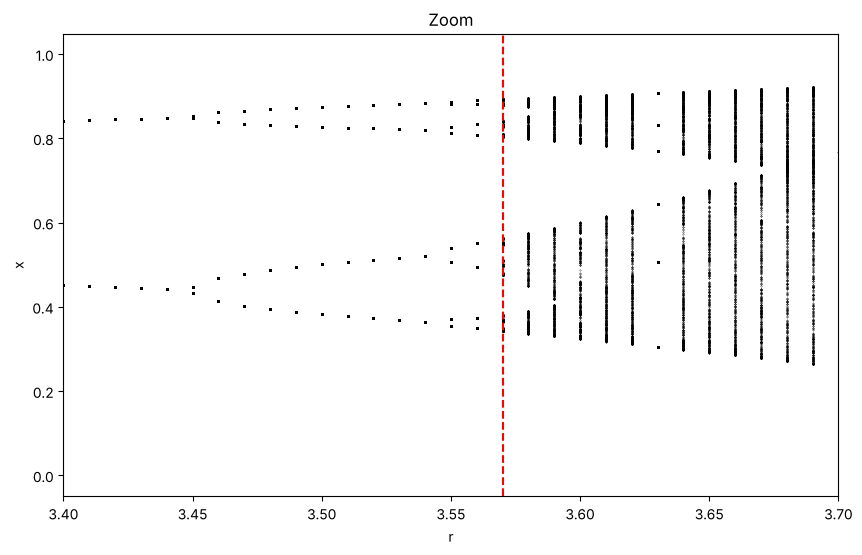

In [9]:
# hice zoom para ver mejor donde empieza
plt.figure(figsize=(10,6))
plt.plot(r_graf, x_graf, "k.", markersize=0.5)
plt.xlim(3.4, 3.7)
plt.axvline(3.57, color="r", linestyle="--")
plt.xlabel("r")
plt.ylabel("x")
plt.title("Zoom")
plt.show()

### (c) Opcional: con arreglos

Ahora en lugar de un for para cada r hago todo el arreglo de r de una vez, usando time para comparar ambos métodos

In [10]:
import time

# metodo 1 (el de arriba) otra vez para medir el tiempo
t0 = time.time()
for r in np.arange(1, 4, 0.01):
    x = 0.5
    for i in range(2000):
        x = r*x*(1-x)
t1 = time.time()
print("tiempo con for:", t1-t0, "s")

# metodo 2 con arreglos
t0 = time.time()
r = np.arange(1, 4, 0.01)
x = 0.5*np.ones(len(r))
for i in range(1000):
    x = r*x*(1-x)
rs = []
xs = []
for i in range(1000):
    x = r*x*(1-x)
    rs.append(r.copy())
    xs.append(x.copy())
t1 = time.time()
print("tiempo con arreglos:", t1-t0, "s")

tiempo con for: 0.13248014450073242 s
tiempo con arreglos: 0.00882863998413086 s


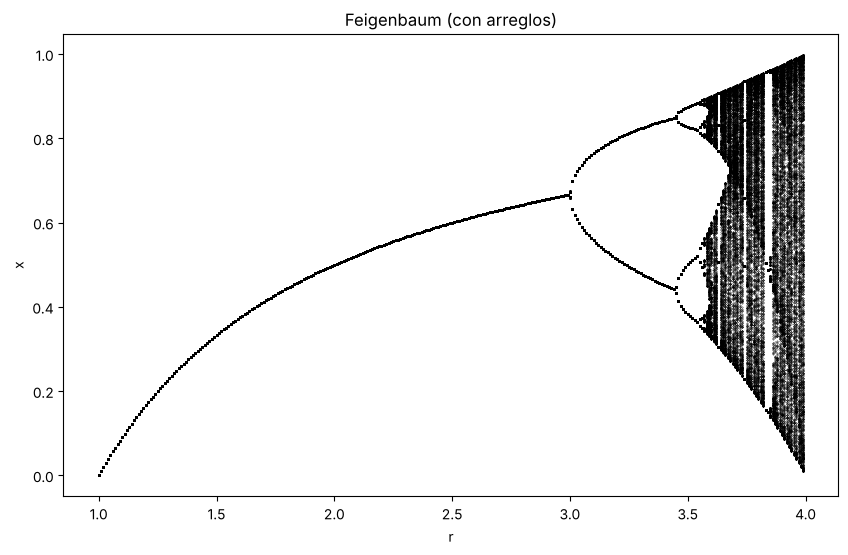

In [11]:
plt.figure(figsize=(10,6))
plt.plot(rs, xs, "k.", markersize=0.5)
plt.xlabel("r")
plt.ylabel("x")
plt.title("Feigenbaum (con arreglos)")
plt.show()

## 3. Conjunto de Mandelbrot

### (a) Blanco y negro

$z_{n+1} = z_n^2 + c$, con $z_0 = 0$. Si |z| pasa de 2 no está en el conjunto. Hago 100 iteraciones.

Primero pruebo con N=100 como dice la sugerencia.

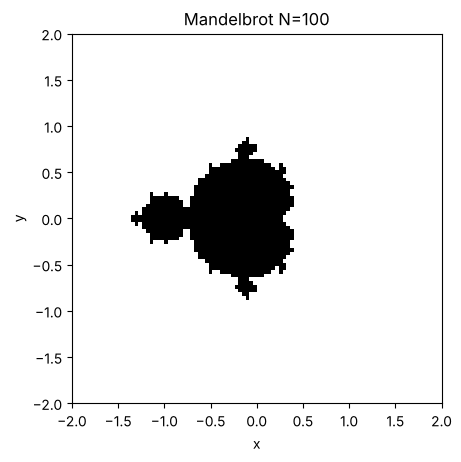

In [12]:
N = 100
iteraciones = 100

xs = np.linspace(-2, 2, N)
ys = np.linspace(-2, 2, N)
imagen = np.zeros([N, N])

for i in range(N):
    for j in range(N):
        c = xs[j] + 1j*ys[i]
        z = 0
        dentro = 1
        for n in range(iteraciones):
            z = z**2 + c
            if abs(z) > 2:
                dentro = 0
                break
        imagen[i,j] = dentro

plt.imshow(imagen, cmap="gray_r", extent=[-2,2,-2,2], origin="lower")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Mandelbrot N=100")
plt.show()

Sí funciona :) ahora con N más grande

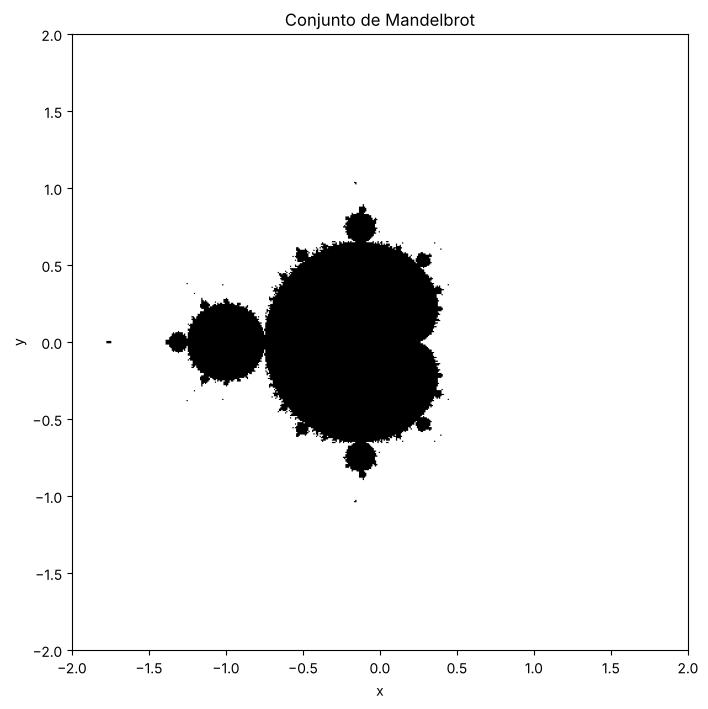

In [13]:
N = 500

xs = np.linspace(-2, 2, N)
ys = np.linspace(-2, 2, N)
imagen = np.zeros([N, N])

for i in range(N):
    for j in range(N):
        c = xs[j] + 1j*ys[i]
        z = 0
        dentro = 1
        for n in range(iteraciones):
            z = z**2 + c
            if abs(z) > 2:
                dentro = 0
                break
        imagen[i,j] = dentro

plt.figure(figsize=(8,8))
plt.imshow(imagen, cmap="gray_r", extent=[-2,2,-2,2], origin="lower")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Conjunto de Mandelbrot")
plt.show()